# VERDE - Baseline Model Training
### Smart Recycling and Waste Segregation Assistant - Week 3 baseline classifier

**Model:** MobileNetV3-Small (ImageNet-pretrained, fine-tuned for 9 waste classes)
**Data:** the exact train / validation / test split exported from the `VERDE - Data Analysis` notebook (Sections 9-10)
**Requires:** GPU and Internet enabled (Internet is needed once, to download pretrained weights)

<a id="section-1"></a>
## Section 1: Setup & Load Split

**Goal:** Prepare a reproducible environment and load the exact split created in the data analysis notebook, rather than regenerating it.

**Inputs to attach:** (1) the `VERDE - Data Analysis` notebook output (contains the split CSVs) and (2) the `adithyachalla/waste-classification` dataset (the CSVs store paths into it).

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.metrics import confusion_matrix, classification_report

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Load the exported split ---
SPLIT_DIR = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis")

train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_split.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_split.csv")
train_balanced_df = pd.read_csv(SPLIT_DIR / "train_balanced_split.csv")

print(f"Train (balanced): {len(train_balanced_df)}  Val: {len(val_df)}  Test: {len(test_df)}")

# --- Confirm the images themselves are reachable, not just the CSVs ---
for name, d in [("train_balanced", train_balanced_df), ("val", val_df), ("test", test_df)]:
    first = Path(d["path"].iloc[0])
    print(f"{name}: first image found = {first.exists()}")

Train (balanced): 2907  Val: 713  Test: 713
train_balanced: first image found = True
val: first image found = True
test: first image found = True


**Finding:** The split loads as 2,907 balanced training images, 713 validation and 713 test images, matching Section 9 of the data analysis notebook exactly, and all image paths resolve.

<a id="section-2"></a>
## Section 2: Data Pipeline

**Goal:** Turn the split DataFrames into batches of normalised 224x224 tensors with integer labels, using the preprocessing recommended in the data analysis.

In [2]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),        # background-matched fill
    transforms.ColorJitter(brightness=0.1, contrast=0.1),   # mild, preserves Vegetation colour cue
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# --- Fixed class -> index mapping, built once so every split (and the Pi) uses the same labels ---
class_names = sorted(train_balanced_df["class"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
print(class_to_idx)

class WasteDataset(Dataset):
    """Loads one image per row of a split DataFrame and applies the given transform."""
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.labels = [class_to_idx[c] for c in df["class"]]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[idx]

BATCH_SIZE = 32

train_loader = DataLoader(WasteDataset(train_balanced_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(WasteDataset(val_df, eval_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(WasteDataset(test_df, eval_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# --- Sanity check: one batch should be [32, 3, 224, 224] images and [32] labels ---
images, labels = next(iter(train_loader))
print(f"Batch images: {tuple(images.shape)}  labels: {tuple(labels.shape)}")
print(f"Batches per epoch (train): {len(train_loader)}")

{'1-Cardboard': 0, '2-Food Organics': 1, '3-Glass': 2, '4-Metal': 3, '5-Miscellaneous Trash': 4, '6-Paper': 5, '7-Plastic': 6, '8-Textile Trash': 7, '9-Vegetation': 8}
Batch images: (32, 3, 224, 224)  labels: (32,)
Batches per epoch (train): 91


**Finding:** Class indices are fixed alphabetically (0 = Cardboard ... 8 = Vegetation) and a training batch has shape (32, 3, 224, 224), giving 91 batches per epoch. Because augmentation runs lazily per fetch, duplicated images from oversampling receive a fresh random augmentation every epoch.

<a id="section-3"></a>
## Section 3: Model Setup

**Goal:** Build the baseline classifier: a pretrained lightweight network with a new 9-class output layer, plus the loss, optimiser and learning-rate schedule.

In [3]:
# WHAT: Load a pretrained MobileNetV3-Small, replace its classifier head with a 9-class
#       output layer, and set up the loss, optimiser and learning-rate schedule.
# WHY:  MobileNetV3-Small is small and fast enough for the Raspberry Pi 5, and this model
#       family has a standard ExecuTorch export path. Fine-tuning a pretrained backbone is
#       far more data-efficient than training from scratch on ~2,900 images. Plain
#       CrossEntropyLoss is used with no class weights, because the EDA (Section 10)
#       recommended against stacking loss weighting on an already-balanced training set.
# HOW:  classifier[3] is the final Linear layer (1000 ImageNet classes), swapped for a
#       9-class one. AdamW with weight decay regularises the fine-tuning, and a cosine
#       schedule lowers the learning rate smoothly over the run.
# ------------------------------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1, progress=True)
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, len(class_names))   # 1000 -> 9 classes
model = model.to(device)

EPOCHS = 12
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params:,}")

Using device: cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 94.3MB/s]

Trainable parameters: 1,527,081


**Finding:** The model runs on GPU with 1,527,081 trainable parameters - small enough for edge deployment. Weight decay and a cosine learning-rate schedule are used for stable fine-tuning.

<a id="section-4"></a>
## Section 4: Training

**Goal:** Fine-tune the model, tracking training and validation metrics each epoch, and keep the checkpoint that generalises best.

In [4]:
# WHAT: Train for 12 epochs, evaluate on the validation set after each one, and save the
#       checkpoint with the best validation accuracy.
# WHY:  Tracking train and validation metrics together shows whether the model is learning
#       or overfitting. Selecting the checkpoint by validation accuracy, not by the last
#       epoch, means the saved model is the best generalising one. The test set is not
#       touched here, so it stays an honest final measurement in Section 6.
# HOW:  model.train() enables training behaviour; model.eval() with no gradients makes
#       validation deterministic and cheaper. The checkpoint stores class_names alongside
#       the weights, so the Raspberry Pi side can rebuild the exact label mapping.
# ------------------------------------------------------------------------------------

def run_epoch(loader, train):
    """Run one pass over a loader; return average loss and accuracy."""
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for images, labels in tqdm(loader, desc="train" if train else "val", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            n += images.size(0)

    return total_loss / n, correct / n

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    saved = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({"model_state": model.state_dict(),
                    "class_names": class_names,
                    "epoch": epoch,
                    "val_acc": val_acc}, "/kaggle/working/best_model.pth")
        saved = "  <- best, saved"

    print(f"Epoch {epoch:2d}/{EPOCHS}  "
          f"train loss {train_loss:.3f} acc {train_acc:.1%}  |  "
          f"val loss {val_loss:.3f} acc {val_acc:.1%}{saved}")

print(f"\nBest validation accuracy: {best_val_acc:.1%}")

Epoch  1/12  train loss 1.090 acc 63.1%  |  val loss 0.724 acc 75.0%  <- best, saved


Epoch  2/12  train loss 0.461 acc 84.6%  |  val loss 0.511 acc 80.4%  <- best, saved


Epoch  3/12  train loss 0.271 acc 91.3%  |  val loss 0.506 acc 81.3%  <- best, saved


Epoch  4/12  train loss 0.196 acc 93.6%  |  val loss 0.441 acc 85.0%  <- best, saved


Epoch  5/12  train loss 0.144 acc 94.9%  |  val loss 0.402 acc 84.3%


...

Epoch  8/12  train loss 0.060 acc 98.3%  |  val loss 0.400 acc 87.5%  <- best, saved


Epoch  9/12  train loss 0.047 acc 98.7%  |  val loss 0.398 acc 87.8%  <- best, saved


Epoch 10/12  train loss 0.047 acc 98.7%  |  val loss 0.391 acc 87.4%


Epoch 11/12  train loss 0.028 acc 99.3%  |  val loss 0.392 acc 87.2%


Epoch 12/12  train loss 0.031 acc 99.4%  |  val loss 0.393 acc 87.2%

Best validation accuracy: 87.8%


<a id="section-5"></a>
## Section 5: Learning Curves

**Goal:** Visualise training behaviour to check for overfitting and justify the number of epochs.

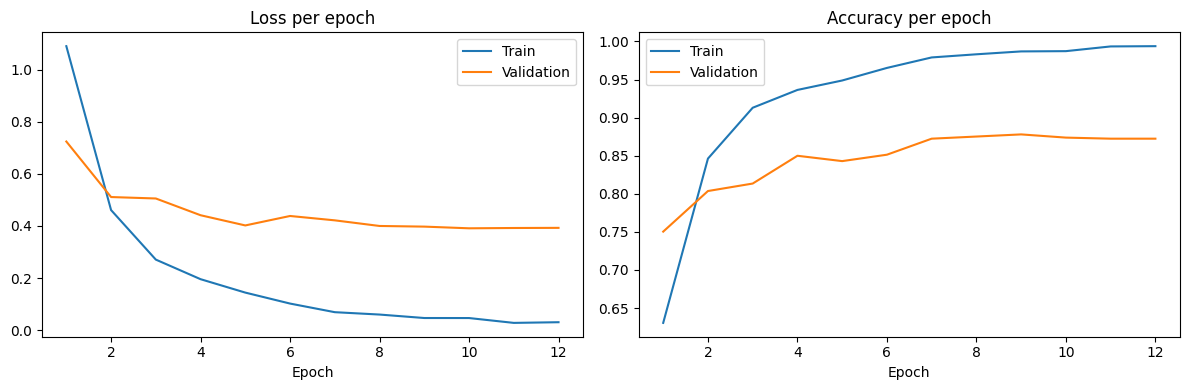

In [5]:
# WHAT: Plot loss and accuracy per epoch for training and validation.
# WHY:  A gap that widens between the train and validation curves is the standard sign of
#       overfitting. This chart is also the main training evidence for the report.
# HOW:  Two side-by-side line plots share the same epoch axis.
# ------------------------------------------------------------------------------------

epochs_range = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_title("Loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="Train")
axes[1].plot(epochs_range, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Validation loss flattens from about epoch 8 while training loss keeps falling, and validation accuracy stays near 87-88%. The curves support stopping at 12 epochs: more training would mainly widen the train/validation gap. The baseline is good enough for Week 3; tuning is deferred to the later improvement phase.

<a id="section-6"></a>
## Section 6: Test Evaluation

**Goal:** Measure the final baseline once on the held-out test set, with per-class metrics and a confusion matrix, focusing on the Paper vs Cardboard pair.

Loaded checkpoint from epoch 9 (val acc 87.8%)


test: 100%|██████████| 23/23 [00:04<00:00,  5.06it/s]



Test accuracy: 87.1%  (validation: 87.8%, EDA proxy: 72.2%)

                       precision    recall  f1-score   support

          1-Cardboard      0.838     0.899     0.867        69
      2-Food Organics      0.906     0.935     0.921        62
              3-Glass      0.846     0.873     0.859        63
              4-Metal      0.833     0.932     0.880       118
5-Miscellaneous Trash      0.813     0.813     0.813        75
              6-Paper      0.938     0.813     0.871        75
            7-Plastic      0.877     0.775     0.823       138
      8-Textile Trash      0.898     0.917     0.907        48
         9-Vegetation      0.940     0.969     0.955        65

             accuracy                          0.871       713
            macro avg      0.877     0.881     0.877       713
         weighted avg      0.873     0.871     0.870       713



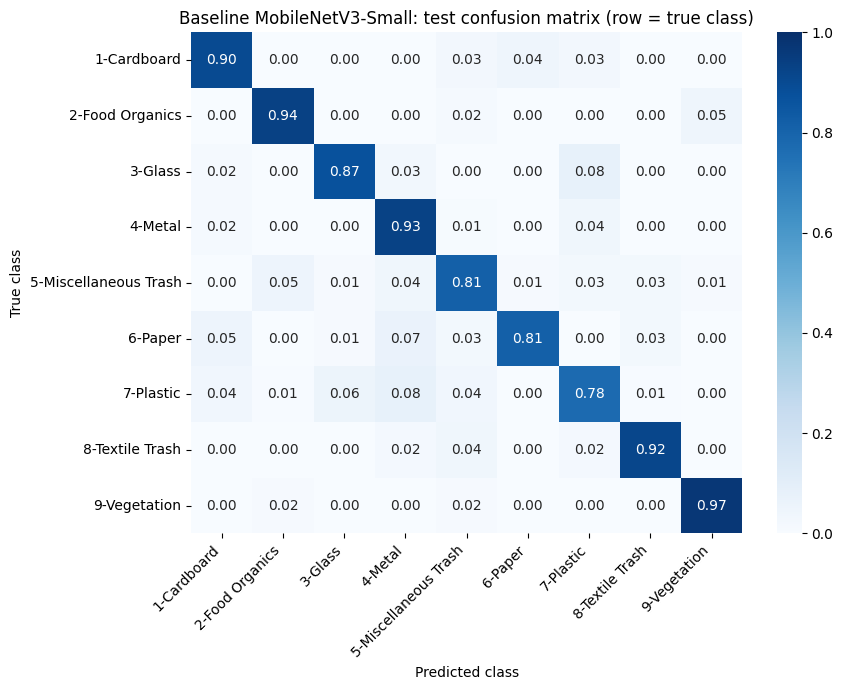

Paper predicted as Cardboard : 4 of 75 Paper test images
Cardboard predicted as Paper : 3 of 69 Cardboard test images


In [6]:
# WHAT: Reload the best checkpoint, evaluate it once on the held-out test set, and produce
#       overall accuracy, per-class metrics and a 9x9 confusion matrix.
# WHY:  The test set was never used for training or checkpoint selection, so this is the
#       honest baseline number. The confusion matrix answers the Week 3 question: how do
#       Paper and Cardboard behave in a real trained model, compared with the data analysis
#       proxy (Section 8: 23% of Paper predicted as Cardboard)?
# HOW:  The model holds epoch-12 weights after training, so the epoch-8 checkpoint is
#       loaded first. Predictions are collected batch by batch with gradients off, then
#       compared with true labels using scikit-learn. The matrix is row-normalised so each
#       row shows where a true class's images ended up.
# ------------------------------------------------------------------------------------

ckpt = torch.load("/kaggle/working/best_model.pth", map_location=device)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"Loaded checkpoint from epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.1%})")

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="test"):
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.tolist())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"\nTest accuracy: {test_acc:.1%}  (validation: {ckpt['val_acc']:.1%}, EDA proxy: 72.2%)\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

# --- Confusion matrix, row-normalised ---
cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Baseline MobileNetV3-Small: test confusion matrix (row = true class)")
plt.ylabel("True class")
plt.xlabel("Predicted class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("/kaggle/working/test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Week 3 focus pair: Paper vs Cardboard, in raw counts ---
i_card, i_paper = class_to_idx["1-Cardboard"], class_to_idx["6-Paper"]
print(f"Paper predicted as Cardboard : {cm[i_paper, i_card]} of {cm[i_paper].sum()} Paper test images")
print(f"Cardboard predicted as Paper : {cm[i_card, i_paper]} of {cm[i_card].sum()} Cardboard test images")